# ENSO prediction
### Project 1 companion notebook

This notebook walks you through a basic ENSO definition, what a model from the Climate Model Intercomparison Project (CMIP) is, loads some relevant data for you from present day and climate change scenario simulations, goes over plotting and re-gridding, and shows you a simple predictive model.

> ### Your task: Make a model to predict the current ENSO!
This model can take any number of inputs and should predict the field from which ENSO is calculated, not just the index number alone.

The main point of this project is to give you hands-on experience in deadline with geospatial data which is fairly friendly as it is regular and gridded. There are a number of different, but interacting fields, that could increase the predictive skill. Your model, or models, can be anything you like, within reason.

Your write-up should be between 1 and 2 pages.

---
## 1. ENSO in a nut-shell

1. **ENSO (El Niño–Southern Oscillation)** is an irregular see-saw of the coupled tropical-Pacific ocean and atmosphere, and the single largest source of year-to-year climate variability on Earth.
2. **Normal state:** trade winds blow westward, piling warm water into a "warm pool" near Indonesia. At the same time, cold water upwells off South America. Rain sits over the warm pool.
3. **El Niño:** the trades slacken, warm water and rainfall shift eastward, and the reorganized tropical heating redirects weather patterns worldwide. This means droughts, floods, fishery collapses, food-price shocks, disease outbreaks, both along the Pacific and world-wide.
4. **La Niña:** the opposite phase. Here we have stronger trade winds, and a colder east Pacific. It has its own global fingerprint.
5. **Period:** events recur every ~2–7 years, peak in boreal winter, and no two are alike.

## 2. The ENSO index: Boxes on the ocean

The community compresses the ENSO phenomenon into a handful of numbers, that are the **area-averaged sea-surface-temperature anomalies inside fixed boxes in the tropical Pacific** along the equator. An *anomaly* is the departure from the seasonal norm, see Section 7.

| Index | Latitude | Longitude | What it watches |
|---|---|---|---|
| **Niño 1+2** | 0–10°S | 90–80°W | coastal Peru where fishermen first named "El Niño" |
| **Niño 3** | 5°N–5°S | 150–90°W | eastern-Pacific heart of classic events |
| **Niño 3.4** | 5°N–5°S | 170–120°W | **the** headline index which you'll normally see. Covers east & central Pacific |
| **Niño 4** | 5°N–5°S | 160°E–150°W | western/central Pacific, warm-pool edge |

NOAA's operational **ONI (Oceanic Niño Index)** = Niño 3.4 anomaly, smoothed with a 3-month running mean. **El Niño** is declared at **ONI ≥ +0.5 °C** and **La Niña** at **≤ −0.5 °C**, sustained for 5 overlapping seasons. In this course, "the ENSO index" means ONI.


In [1]:
# This installs conda and RESTARTS the runtime. When the runtime comes back, run again from the top:
# this cell will then say "Everything looks OK" and you carry on.
import sys
IN_COLAB = "google.colab" in sys.modules   # local-run fix (Claude Opus 5.5): only install conda on Colab
if IN_COLAB:
    try:
        import condacolab; condacolab.check()
    except Exception:
        %pip install -q condacolab
        import condacolab; condacolab.install()

In [2]:
# Installing some libraries
if IN_COLAB:   # local-run fix (Claude Opus 5.5): a local environment already has these
    !mamba install -q -y -c conda-forge esmpy xesmf
    %pip install -q zarr gcsfs cartopy cftime intake-esm xmip

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
print("ready.")

ready.


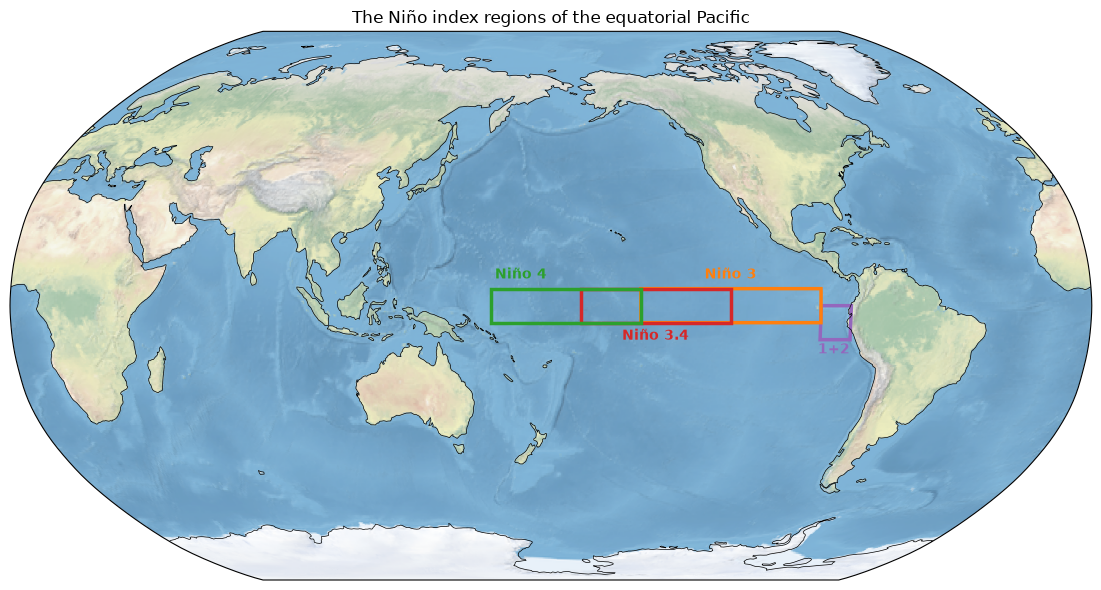

In [3]:
# ---- The Niño boxes, in 0-360°E longitude convention ----
NINO = {  # name: (lon_min, lon_max, lat_min, lat_max, color)
    "Niño 1+2": (270, 280, -10,  0, "tab:purple"),
    "Niño 3":   (210, 270,  -5,  5, "tab:orange"),
    "Niño 3.4": (190, 240,  -5,  5, "tab:red"),
    "Niño 4":   (160, 210,  -5,  5, "tab:green"),
}

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.stock_img()                       # a 'realistic' shaded-relief Earth that ships with cartopy
ax.coastlines(lw=0.5)
for name, (x0, x1, y0, y1, c) in NINO.items():
    ax.add_patch(mpatches.Rectangle((x0, y0), x1-x0, y1-y0,
                 transform=ccrs.PlateCarree(), fill=False, edgecolor=c, lw=2.5))
ax.text(275, -14, "1+2", color="tab:purple", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(240,   8, "Niño 3", color="tab:orange", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(215, -10, "Niño 3.4", color="tab:red", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.text(170,   8, "Niño 4", color="tab:green", transform=ccrs.PlateCarree(), ha="center", weight="bold")
ax.set_global()
ax.set_title("The Niño index regions of the equatorial Pacific")
plt.tight_layout()

> ### Note:
We use the **Robinson projection**: a deliberate compromise that distorts *everything a little* so the whole Earth looks natural at a glance. This is good for orientation, but bad for reading data off tropics-only plots, so later sections switch to be zoomed on the Pacific.

---
## 3. CMIP6 model, with five scenarios (aka experiments)

Each group will focus on **one** CMIP model, IPSL-CM6A (Fr), UKESM1 (UK), CESM2 (US), or GFDL-ESM4 (US). These are all the models behind the IPCC AR6 report. We have the following scenarios:

| Experiment | Years | Description |
|---|---|---|
| `historical` | 1850–2014 | the model's run of the industrial era, driven by observed forcings (greenhouse gases, aerosols, volcanoes, solar etc) |
| `ssp126` | 2015–2100 | strong-mitigation future (low emissions) |
| `ssp245` | 2015–2100 | "middle of the road" future |
| `ssp370` | 2015–2100 | regional-rivalry, high-emissions future |
| `ssp585` | 2015–2100 | very high emissions future |

Note, `historical` refers to that the model is run using the greenhouse gas forcing of the past, and is not observational data. The `ssp` ("Shared Socioeconomic Pathways") look to the future, and differ only in *forcing*, i.e. how the world changes its greenhouse gas emissions, and the physics is identical. Each scenario continues seamlessly from the end of `historical`.


---
## 4. The data fields

The class variable set with some descriptions:

| id | Quantity | Units | Table | Grid | ENSO relevance |
|---|---|---|---|---|---|
| `tos` | sea-surface temperature | °C | `Omon` | `gn` ⚠️ | the index itself is built from this |
| `zos` | sea-surface height | m | `Omon` | `gn` ⚠️ | sloshing warm water literally tilts the sea surface. It's a proxy for upper-ocean heat |
| `mlotst` | mixed-layer depth | m | `Omon` | `gn` ⚠️ | how deep the wind-stirred surface layer reaches |
| `thetao` | ocean potential temperature (3-D) | °C | `Omon` | `gn` ⚠️ | the subsurface memory of ENSO (thermocline depth, heat content) |
| `pr` | precipitation | kg m⁻² s⁻¹ | `Amon` | `gr` ✅ | Rain... Major impact we see |
| `tauu` | eastward surface wind stress | Pa | `Amon` | `gr` ✅ | the trades: ENSO's driver *and* responder |
| `tauv` | northward surface wind stress | Pa | `Amon` | `gr` ✅ | meridional component North-South |

**The grid column in important.** `gr` = regridded to a regular latitude × longitude grid: `sel(lat=..., lon=...)` just works. `gn` = the model's **native curvilinear ocean grid**: latitude and longitude are *two-dimensional arrays*, ordinary coordinate slicing fails, and regions must be selected with masks. This is a problem for most things. See Section 7 for ideas.

**Units:** precipitation arrives in kg m⁻² s⁻¹ (multiply by 86 400 for mm/day), and while IPSL's `tos` is in °C, other datasets are in Kelvin.

We load the five **2-D** fields only. `thetao` is listed, path included below, but **deliberately not loaded**: it's a 4-D field (time × 59 depth levels × y × x) roughly ~50× the data volume of `tos`. If your implementation project needs it, you can subset (tropical Pacific, upper ~300 m) *before* computing. Note `xarray` is **lazy**, so opening a store below moves no data, this only happens when you `.load()`, compute, or plot.

> **Pangeo.** Working with climate model data is very complicated. This notebook uses the same open-source stack the climate research community uses, so skills transfer.
- **intake-esm** finds and opens CMIP datasets from the cloud catalog.
- **xmip** cleans CMIP's notorious cross-model inconsistencies (coordinate names, longitude conventions, dimension order).
- **xgcm** does grid-aware calculus on staggered model grids (derivatives, transports, budget closures: not needed in this notebook, essential if your project computes heat budgets).
- **xESMF** is the community regridder (bilinear/conservative and more): We install it via conda in the setup and use it in Section 7½.
- **cf-xarray** smooths metadata handling. The free, excellent

**Project Pythia CMIP6 Cookbook** demonstrates most of this stack.


In [4]:
import intake
import xarray as xr
from xmip.preprocessing import combined_preprocessing

# ---- Change MODEL to pick a different CMIP model. ----
MODEL = "CESM2"    # Group 5

# Each model publishes different ensemble members, and **GFDL-ESM4 never ran ssp126** so it's missing.
# This catalog-verified lookup makes things easier for you:
WORLDS = {   # model: (default member, experiments with all six variables complete)
    "IPSL-CM6A-LR": ("r1i1p1f1", ["historical","ssp126","ssp245","ssp370","ssp585"]),
    "UKESM1-0-LL":  ("r1i1p1f2", ["historical","ssp126"]),#,"ssp245","ssp370","ssp585"]),
    "CESM2":        ("r4i1p1f1", ["historical","ssp126","ssp245","ssp370","ssp585"]),
    "GFDL-ESM4":    ("r1i1p1f1", ["historical","ssp245","ssp370","ssp585"]),
}
MEMBER, EXPS = WORLDS[MODEL]
VARS = ["tos", "zos", "mlotst", "pr", "tauu", "tauv"]

cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
found = cat.search(source_id=MODEL, member_id=MEMBER, experiment_id=EXPS,
                   variable_id=VARS, table_id=["Omon", "Amon"], grid_label=["gn", "gr"])
# Some models (CESM2) publish a variable on BOTH its native grid and a regridded one,
# so we count unique experiment/variable pairs, not rows.
expected = len(EXPS) * len(VARS)
n_unique = found.df.drop_duplicates(["experiment_id", "variable_id"]).shape[0]
assert n_unique == expected, (
    f"expected {expected} variables, found {n_unique}. Run found.df to see what exists for "
    f"{MODEL}/{MEMBER} and trim EXPS (or VARS) to what this model actually provides.")

# chunks={} keeps each store's native chunking. dask's "auto" rechunking cannot size
# cftime (object-dtype) time axes: The scenario runs extend to year 2300, beyond pandas' range.
datasets = found.to_dataset_dict(preprocess=combined_preprocessing, progressbar=False,
                                 storage_options={"token": "anon"},
                                 xarray_open_kwargs={
                                     "chunks": {},
                                     # drop bounds variables: some CMIP stores are extended to 2300 and
                                     # some are not, so their bounds conflict on merge, and we never use
                                     # them (weights come from areacello, timing from the time coordinate).
                                     "drop_variables": ["time_bnds", "time_bounds", "lat_bnds", "lon_bnds",
                                                        "bounds_lat", "bounds_lon",
                                                        "bounds_nav_lat", "bounds_nav_lon"]})

# one ocean dataset and one atmosphere dataset per experiment
ocean, atmos = {}, {}
for name in sorted(datasets):              # ".gn" sorts before ".gr", so when a variable exists on
    ds = datasets[name]                    # both grids, the native one wins (it matches areacello)
    experiment = name.split(".")[3]
    bucket = ocean if ".Omon." in name else atmos
    if experiment in bucket:
        continue                           # duplicate grid for this experiment, already have it
    ds = ds.sel(time=slice(None, "2100-12"))   # some stores extend to 2300, others don't;
                                               # keep only the range where every variable is complete
    ds = ds.squeeze(drop=True)                 # drop the singleton member/dcpp dimensions intake-esm adds
    if ".Omon." in name:
        ocean[experiment] = ds                 # holds tos, zos, mlotst (native 2-D curvilinear grid)
    else:
        # regular atmosphere grid: xmip left 1-D coordinates named y/x and added redundant,
        # transposed 2-D lat/lon copies. Keep the clean 1-D version under the proper names.
        atmos[experiment] = ds.drop_vars(["lat", "lon"]).rename({"y": "lat", "x": "lon"})

# ocean grid-cell areas for THIS model (areas are a property of the grid, so any one store will do)
import gcsfs
fs = gcsfs.GCSFileSystem(token="anon")
cell_areas = cat.search(source_id=MODEL, variable_id="areacello", grid_label="gn").df
area = combined_preprocessing(xr.open_zarr(fs.get_mapper(cell_areas.zstore.iloc[0]),   # fix (Claude Opus 5.5): CESM2's
                    consolidated=True))["areacello"].squeeze()                  # areacello needs the same (y, x) dims

# Look at units before trusting anything!!
for ds in (ocean["historical"], atmos["historical"]):
    for v in ds.data_vars:
        print(f"{v:<7} units={ds[v].attrs.get('units','?'):<14} dims={list(ds[v].dims)}")

zos     units=m              dims=['time', 'y', 'x']
tos     units=°C             dims=['time', 'y', 'x']
mlotst  units=m              dims=['time', 'y', 'x']
tauu    units=Pa             dims=['time', 'lat', 'lon']
tauv    units=Pa             dims=['time', 'lat', 'lon']
pr      units=kg/m²/s        dims=['time', 'lat', 'lon']


> **Design decision: We're loading the intake-esm which queries the live cloud catalog** and **xmip**'s `combined_preprocessing` standardizes every dataset's coordinates (2-D `lat`/`lon` on ocean grids, longitudes in 0–360°, consistent dimension names). This cleaning makes multi-model work survivable, and the reason your project's five-model code can look like its one-model code.


Note what just printed: the three ocean fields carry 2-D latitude/longitude (the curvilinear grid, exactly as warned), the three atmosphere fields are regular. xmip has already standardized the coordinate names, so grabbing them takes two lines:


In [5]:
# xmip has already standardized the ocean grid's coordinates: 2-D arrays named lat/lon, longitudes 0-360.
LAT2D = ocean["historical"].lat
LON360 = ocean["historical"].lon
print("ocean grid shape:", LAT2D.shape)

ocean grid shape: (384, 320)


---
## 5. Some figures from the end of the scenario run

We plot, for illustration, one map snap-shot per experiment: the **final December**, Dec **2014** for `historical`, and Dec **2100** for each SSP.


Note: The ocean-grid maps also apply a **display-only seam mask**. These are cells where the native grid wraps its longitude seam, plus cells jumping across its northern fold, project as map-wide horizontal stripes, so we blank both for plotting, else it looks weird.


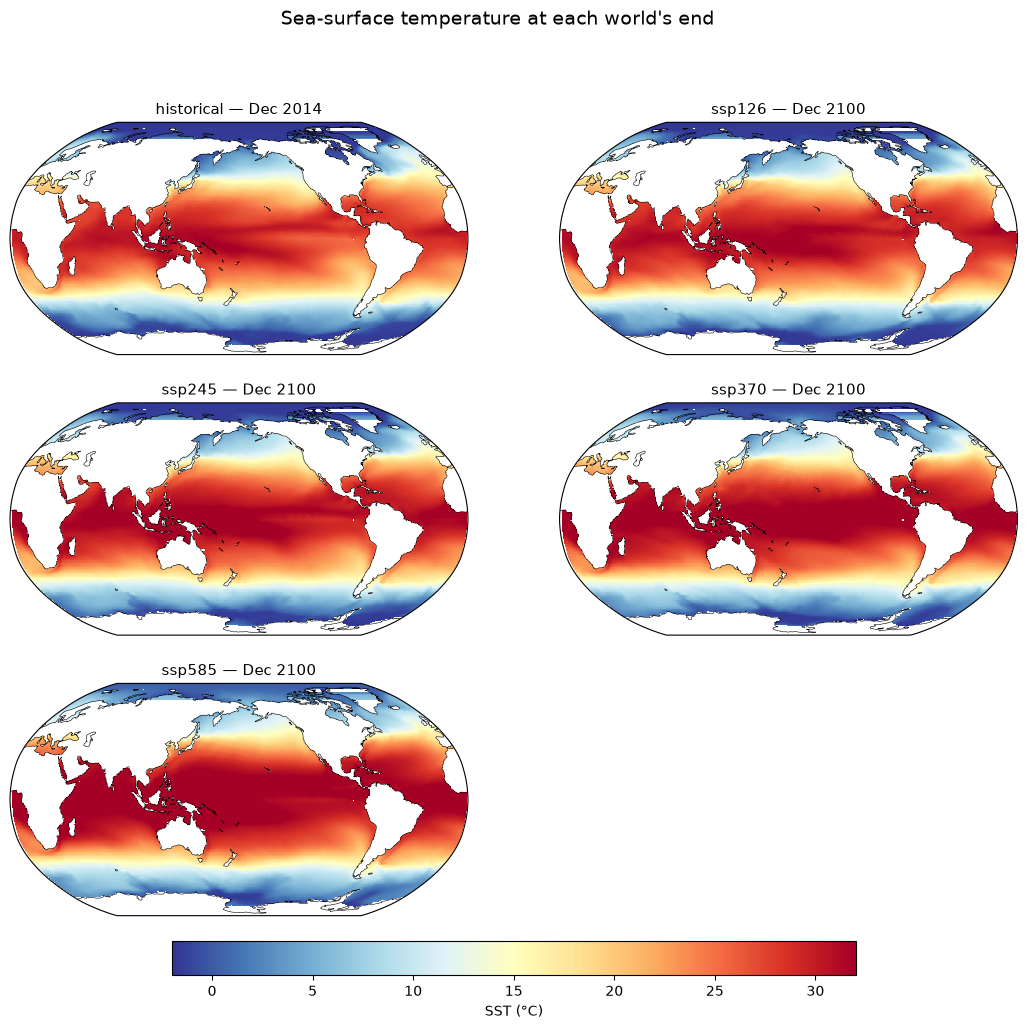

In [6]:
# Cells where the curved ocean grid wraps its seam (or folds near the poles) smear into
# map-wide stripes when plotted. We blank those cells FOR DISPLAY ONLY
jump_lon = np.abs(np.diff(LON360.values, axis=1)) > 180
jump_lat = np.abs(np.diff(LAT2D.values,  axis=1)) > 10
bad = jump_lon | jump_lat
HIDE = np.zeros(LON360.shape, bool); HIDE[:, 1:] |= bad; HIDE[:, :-1] |= bad

def panels(fields, title, cmap, vmin, vmax, units, on_ocean_grid):
    n = len(fields); rows = (n + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(13, 3.7 * rows),
        subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]: ax.set_visible(False)
    for ax, (label, f) in zip(axes, fields.items()):
        if on_ocean_grid:
            f = np.where(HIDE, np.nan, np.asarray(f))
            m = ax.pcolormesh(LON360, LAT2D, f, transform=ccrs.PlateCarree(),
                              cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        else:
            m = ax.pcolormesh(f.lon, f.lat, f, transform=ccrs.PlateCarree(),
                              cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
        ax.coastlines(lw=0.4); ax.set_global(); ax.set_title(label, fontsize=11)
    cb = fig.colorbar(m, ax=list(axes[:n]), orientation="horizontal", fraction=0.04, pad=0.03)
    cb.set_label(units); fig.suptitle(title, fontsize=14)

def last_december(ds, experiment, variable):
    month = "2014-12" if experiment == "historical" else "2100-12"
    return ds[experiment][variable].sel(time=month).squeeze().load()

labels = {e: f"{e} — Dec {'2014' if e=='historical' else '2100'}" for e in EXPS}

panels({labels[e]: last_december(ocean, e, "tos") for e in EXPS},
       "Sea-surface temperature at each world's end", "RdYlBu_r", -2, 32, "SST (°C)", True)

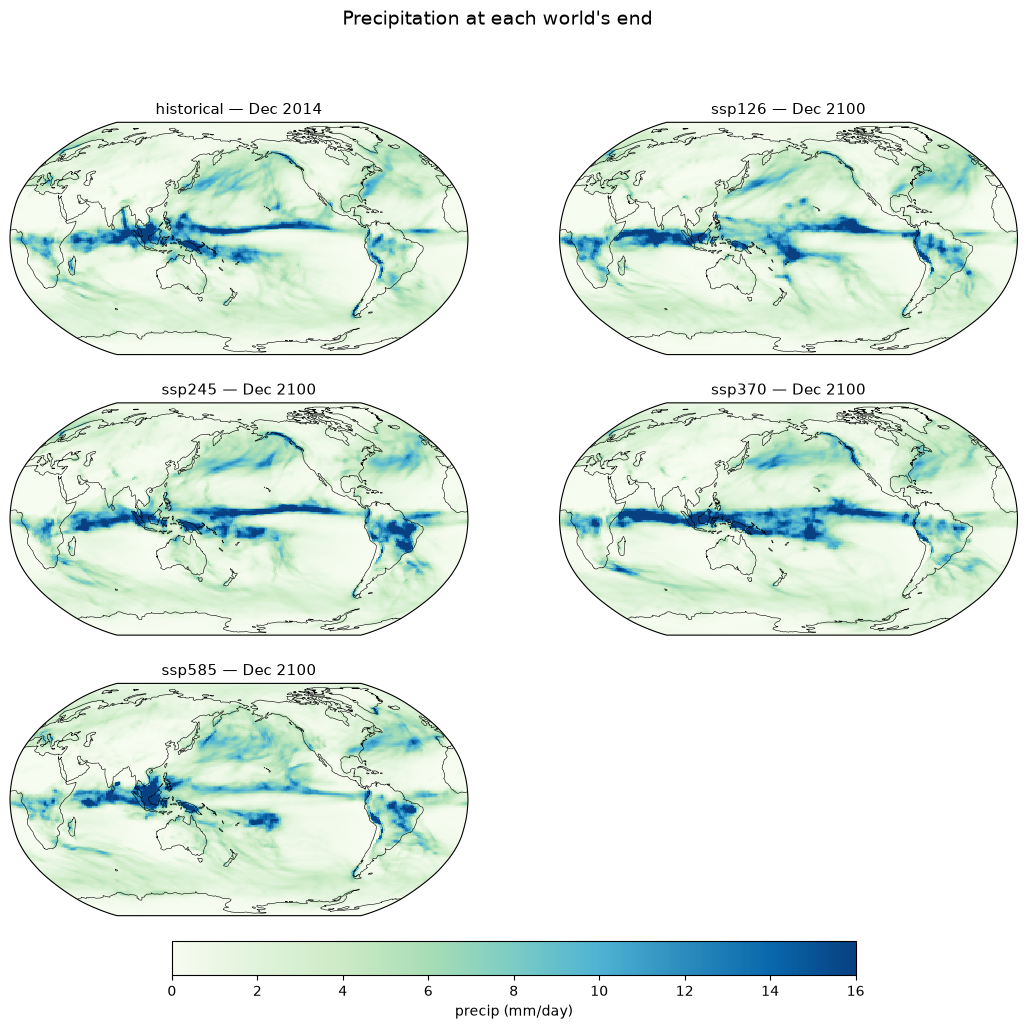

In [7]:
panels({labels[e]: last_december(atmos, e, "pr") * 86400 for e in EXPS},
       "Precipitation at each world's end", "GnBu", 0, 16, "precip (mm/day)", False)

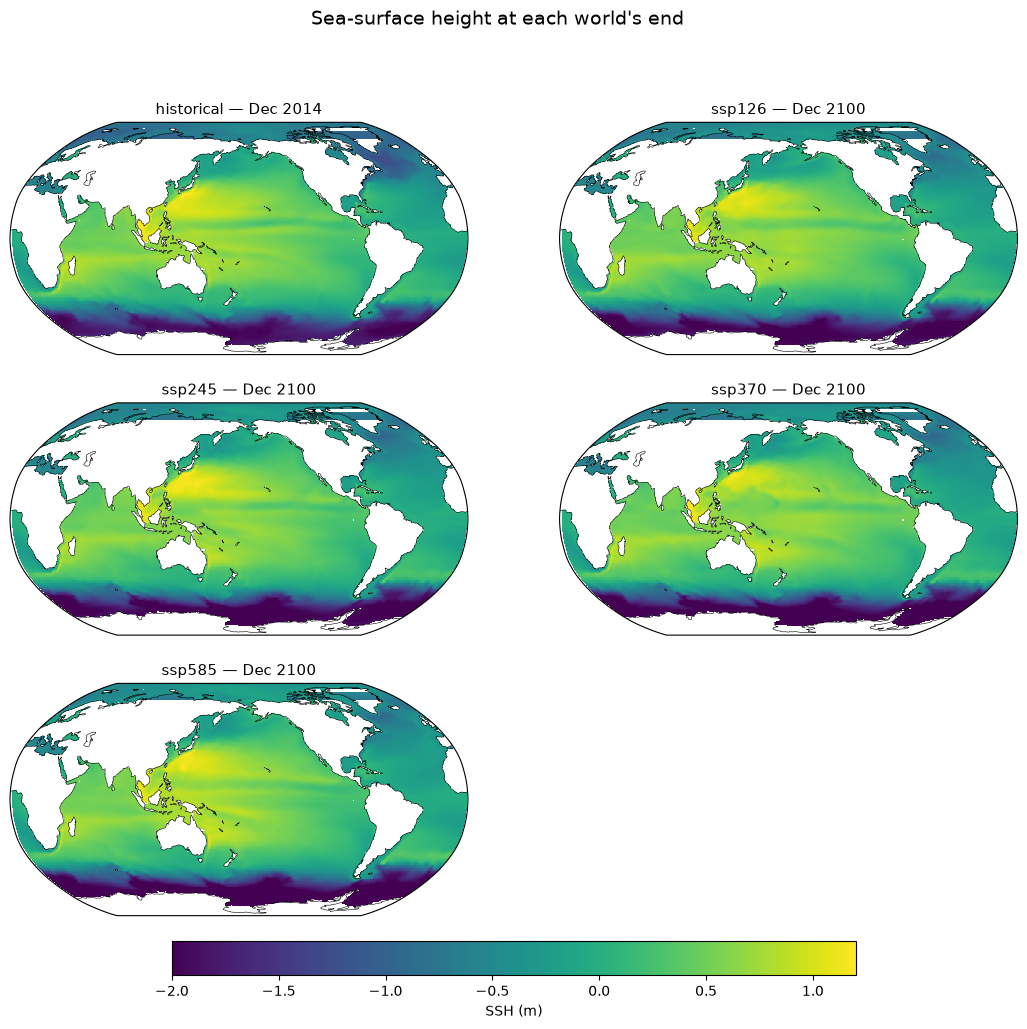

In [8]:
panels({labels[e]: last_december(ocean, e, "zos") for e in EXPS},
       "Sea-surface height at each world's end", "viridis", -2, 1.2, "SSH (m)", True)

---
## Note: Every map above is one "frame"

Each panel in Section 5 is a **single month** sliced out of a monthly record that runs, in this archive, from 1850 to 2100 (and for some scenarios on to 2300). Roughly 3,000 months. Below, the raw (no anomaly removed) SST averaged over the Niño 3.4 box, month by month, through `historical` and `ssp585`, with dots marking the exact two frames the SST maps above showed.

The fast sawtooth that dominates the line (see inset) is the **seasonal cycle**, repeating on schedule every year and *larger* than the interannual wiggles we actually care about. Staring at it here is the motivation for everything in Section 6.


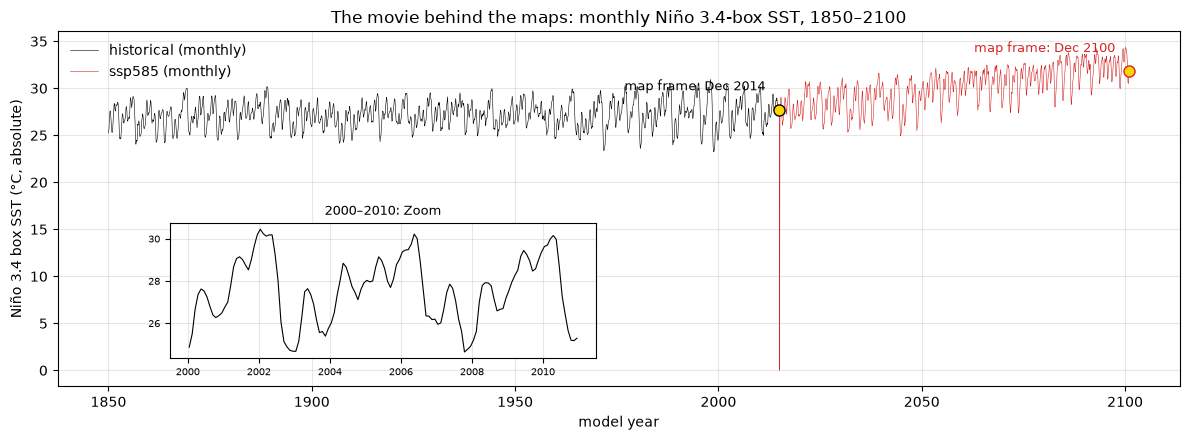

In [9]:
# Area-weighted mean SST in the Nino 3.4 box
# applied here to ABSOLUTE SST (no anomaly yet)
lon0, lon1, lat0, lat1, _ = NINO["Niño 3.4"]
in_box = (LAT2D >= lat0) & (LAT2D <= lat1) & (LON360 >= lon0) & (LON360 <= lon1)
box_area = area.where(in_box)
box_mean = lambda da: (da * box_area).sum(dim=box_area.dims) / box_area.sum()

sst_hist = box_mean(ocean["historical"].tos).load()
sst_585  = box_mean(ocean["ssp585"].tos.sel(time=slice("2015", "2100"))).load()
years = lambda da: da.time.dt.year + (da.time.dt.month - 0.5) / 12

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(years(sst_hist), sst_hist, color="k", lw=0.4, label="historical (monthly)")
ax.plot(years(sst_585),  sst_585,  color="tab:red", lw=0.4, label="ssp585 (monthly)")
for label, series, month, color in [("map frame: Dec 2014", sst_hist, "2014-12", "k"),
                                    ("map frame: Dec 2100", sst_585,  "2100-12", "tab:red")]:
    point = series.sel(time=month).squeeze()
    ax.plot(float(years(point)), float(point), "o", ms=8, mfc="gold", mec=color, zorder=5)
    ax.annotate(label, (float(years(point)), float(point)),
                textcoords="offset points", xytext=(-10, 14), ha="right", fontsize=9, color=color)
ax.set_xlabel("model year"); ax.set_ylabel("Niño 3.4 box SST (°C, absolute)")
ax.set_title("The movie behind the maps: monthly Niño 3.4-box SST, 1850–2100")
ax.legend(frameon=False, loc="upper left"); ax.grid(alpha=0.3)

inset = ax.inset_axes([0.1, 0.08, 0.38, 0.38])
decade = sst_hist.sel(time=slice("2000", "2010"))
inset.plot(years(decade), decade, color="k", lw=0.8)
inset.set_title("2000–2010: Zoom", fontsize=9)
inset.tick_params(labelsize=7); inset.grid(alpha=0.3)
plt.tight_layout()

Above we see a clear trend. HOwever: You can tell a 1.5 °C world from a ~4 °C by looking at a spatial plot? Probaly not. The spatial pattern of climate (warm tropics, cold poles, warm-pool-and-cold-tongue Pacific) dominate the *change* in climate. This is why we look at the anomalies.

---
## 6. An anomaly

**An anomaly is the departure from what is normal for that location and that time of year.** For example:

1. Choose a **base period** such as, **1985–2014**, the last 30 years of `historical`.
2. For each of the 12 calendar months, average every January, every February, … in the base period. The result (12 maps) is the **climatology**. So the "normal."
3. Subtract from every field its month's climatology:

$$\mathrm{anomaly}(x,y,t) = \mathrm{value}(x,y,t) - \mathrm{climatology}(x,y,\mathrm{month}(t))$$

Notice: the eastern equatorial Pacific swings by *several* °C every year **on schedule**. An El Niño is a ~1–2.5 °C irregular signal. Subtracting the climatology lets the interesting irregularity stands out. Most things discussing ENSO temperature are relative to a stated base period.

The base period here is 1985–2014, and matches the current WMO-style 30-year convention and sits at the end of `historical`. But "normal" is moving: In a warming world, a late base period makes the past look cold. NOAA re-standardizes its operational base every 5 years for exactly this reason. Your project must take a documented position on this. Comparing your numbers is only meaningful if the base periods match. In class, use a standard of 1985–2014 unless reported otherwise.


In [10]:
BASE = slice("1985-01", "2014-12")
clim = ocean["historical"].tos.sel(time=BASE).groupby("time.month").mean("time")
ssta = (ocean["historical"].tos.groupby("time.month") - clim).rename("ssta")
print("climatology:", dict(clim.sizes), "| anomaly field:", dict(ssta.sizes))

climatology: {'month': 12, 'y': 384, 'x': 320} | anomaly field: {'time': 1980, 'y': 384, 'x': 320}


---
## 7. The Niño boxes, computed on different grids

The area-averaged SST anomaly inside each box. On the native ocean grid there is no `sel(lat=slice(-5,5))`. We build a **boolean mask** from the 2-D coordinate arrays and take a **weighted** average, with the model's own grid-cell areas (`areacello`) as weights.

> **Area weighting.** Grid cells differ in size (less than you'd fear in the deep tropics, more as the mesh refines meridionally toward the equator). Weighting by true cell area is the way to go. An unweighted mean assumes all cells are equal. In the Niño boxes the numerical difference is small, but errors compound and are sneaky.


strongest simulated El Niño month: 1998-01 | peak Niño3.4 anomaly: 3.67 °C


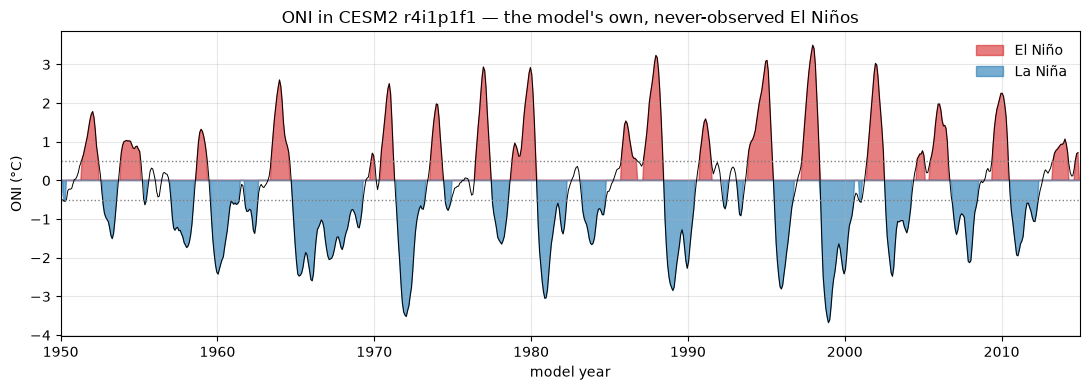

In [11]:
# NOTE: this cell does the first real data crunching
# No output until it finishes.

def nino_index(name):
    lon0, lon1, lat0, lat1, _ = NINO[name]
    inside = (LAT2D >= lat0) & (LAT2D <= lat1) & (LON360 >= lon0) & (LON360 <= lon1)
    w = area.where(inside)
    return ((ssta * w).sum(dim=w.dims) / w.sum()).load()

indices = {name: nino_index(name) for name in NINO}
oni = indices["Niño 3.4"].rolling(time=3, center=True).mean()   # ONI: 3-month running mean

fig, ax = plt.subplots(figsize=(11, 4))
t = oni.time.dt.year + (oni.time.dt.month - 0.5)/12
ax.fill_between(t, 0, oni.where(oni >=  0.5, 0), color="tab:red",  alpha=.6, label="El Niño")
ax.fill_between(t, 0, oni.where(oni <= -0.5, 0), color="tab:blue", alpha=.6, label="La Niña")
ax.plot(t, oni, "k", lw=0.7)
for y in (0.5, -0.5): ax.axhline(y, ls=":", lw=1, color="gray")
ax.set_xlim(1950, 2015); ax.set_xlabel("model year"); ax.set_ylabel("ONI (°C)")
ax.set_title(f"ONI in {MODEL} {MEMBER} — the model's own, never-observed El Niños")
ax.legend(frameon=False); ax.grid(alpha=0.3); plt.tight_layout()

peak = str(indices["Niño 3.4"].idxmax("time").values)[:7]
print("strongest simulated El Niño month:", peak,
      "| peak Niño3.4 anomaly: %.2f °C" % float(indices["Niño 3.4"].max()))

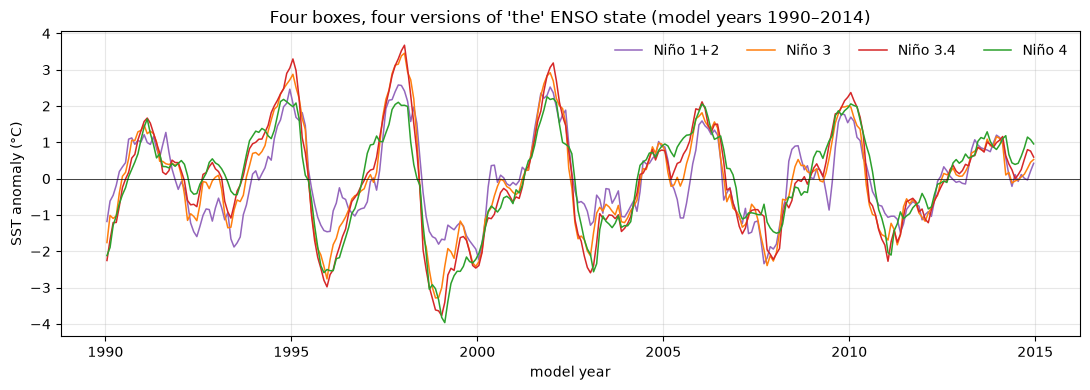

In [12]:
# All four indices during one simulated event-rich stretch
fig, ax = plt.subplots(figsize=(11, 4))
for name, (_, _, _, _, c) in NINO.items():
    sel = indices[name].sel(time=slice("1990", "2014"))
    ax.plot(sel.time.dt.year + (sel.time.dt.month-0.5)/12, sel, color=c, lw=1.1, label=name)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("SST anomaly (°C)"); ax.set_xlabel("model year")
ax.set_title("Four boxes, four versions of 'the' ENSO state (model years 1990–2014)")
ax.legend(frameon=False, ncol=4); ax.grid(alpha=0.3); plt.tight_layout()

---
## Converting between Grids

Our seven variables live on **two different grids** (Section 4). The moment you want them to talk to each other -> correlate SST with rainfall, stack both into one ML feature tensor etc one of them must move. This is **regridding** and every method invents or destroys information somewhere.

> **xESMF, the community standard.** Regridding is a pain. We regrid with **xESMF**, wrapping NOAA's ESMF library. The same `Regridder` object does `bilinear` (used here: smooth interpolation, right for continuous fields like SST), `conservative` (preserves area integrals good choice for fluxes and budgets), and `nearest_s2d` (moves exact values, no invention). `periodic=True` tells it the globe wraps in longitude; `ignore_degenerate=True` tolerates the collapsed cells near the ocean grid's folded poles. Direction of travel: fine ocean grid → coarser atmosphere grid. The reverse would manufacture resolution that does not exist. Tip: Don't regrid inside a training loop.


In [13]:
#import xesmf as xe
import os
if "ESMFMKFILE" not in os.environ:                       # conda sets this on activation;
    os.environ["ESMFMKFILE"] = os.path.join(sys.prefix, "lib", "esmf.mk")  # never activated; local-run fix (Claude Opus 5.5)
import esmpy.api.locstream   # newer esmpy stopped auto-importing its api subpackage; xesmf still expects it
import xesmf as xe

# build the ocean->atmosphere regridder. Apply it to any field on the ocean grid
regridder = xe.Regridder(ocean["historical"], atmos["historical"], "bilinear",
                         periodic=True, ignore_degenerate=True)

ssta_peak = ssta.sel(time=peak).squeeze().load()
ssta_reg = regridder(ssta_peak)
print("regridded:", dict(ssta_peak.sizes), "->", dict(ssta_reg.sizes))

regridded: {'y': 384, 'x': 320} -> {'lat': 192, 'lon': 288}


In [14]:
import esmpy, xesmf; print(esmpy.__version__, xesmf.__version__)

8.9.1 0.9.2


pattern correlation, SST vs rainfall anomaly (tropical Pacific, 1998-01): r = +0.66


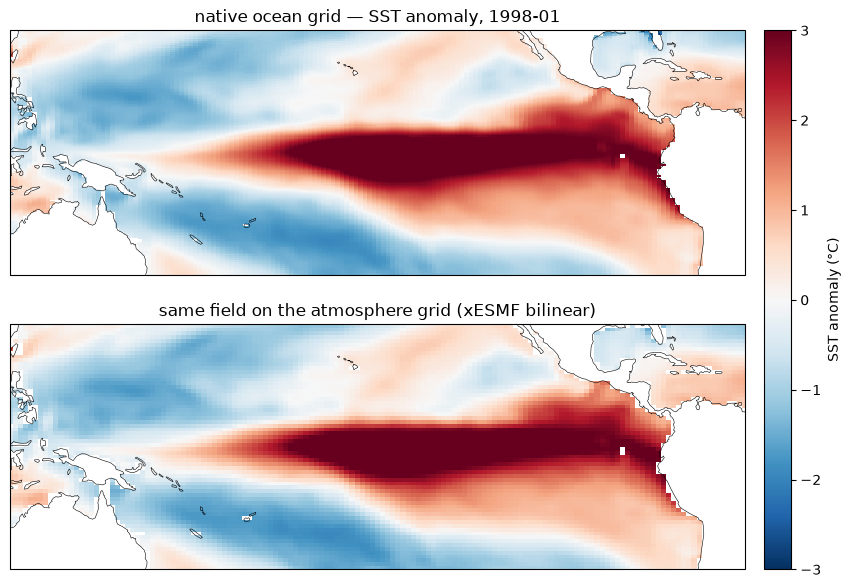

In [15]:
# Before and after
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})

ax1.pcolormesh(LON360, LAT2D, np.where(HIDE, np.nan, ssta_peak), transform=ccrs.PlateCarree(),
               cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax1.set_title(f"native ocean grid — SST anomaly, {peak}")

m = ax2.pcolormesh(ssta_reg.lon, ssta_reg.lat, ssta_reg, transform=ccrs.PlateCarree(),
                   cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax2.set_title("same field on the atmosphere grid (xESMF bilinear)")

for ax in (ax1, ax2):
    ax.coastlines(lw=0.4); ax.set_extent([120, 300, -30, 30], ccrs.PlateCarree())
fig.colorbar(m, ax=[ax1, ax2], fraction=0.03, pad=0.02, label="SST anomaly (°C)")

# Huzzah! SST and rainfall now share a grid, so point-wise statistics are OK!
pr_clim = atmos["historical"].pr.sel(time=BASE).groupby("time.month").mean("time")
pr_anom = ((atmos["historical"].pr.groupby("time.month") - pr_clim)
           .sel(time=peak).squeeze() * 86400).load()
r = xr.corr(ssta_reg.sel(lat=slice(-15, 15), lon=slice(140, 280)),
            pr_anom.sel(lat=slice(-15, 15), lon=slice(140, 280)))
print(f"pattern correlation, SST vs rainfall anomaly (tropical Pacific, {peak}): r = {float(r):+.2f}")

---
# Examples of predictive models to get you started

### Persistence
The baseline for forecast skill is **persistence.**
That is, "next month's Pacific looks like this month's": forecast(t + lead) = ONI(t).
The skill here is simply how correlated the index is with its own future.

### Linear Inverse Model
The classic statistical ENSO forecaster (Penland & Sardeshmukh 1995) assumes linear dynamics plus some noise. It estimates the one-month propagator G from data, forecast by applying it repeatedly.
Here, the state vector is the four Niño indices, which we fit on the first 100 years.



persistence stays above r = 0.5 out to ~5 months lead


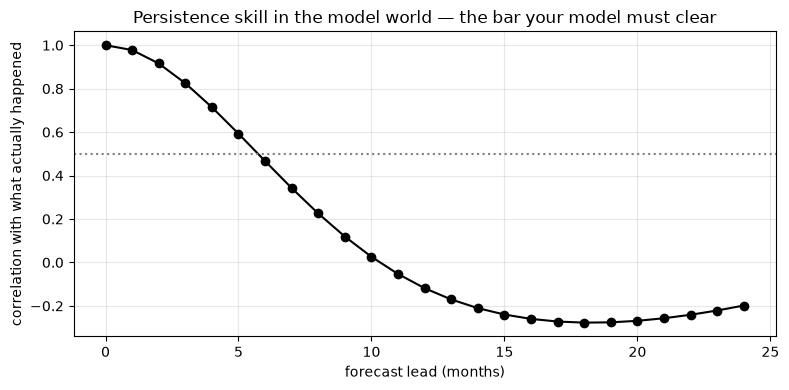

In [16]:

# Persistence

leads = np.arange(0, 25)
skill = [float(xr.corr(oni, oni.shift(time=-int(l)))) for l in leads]

plt.figure(figsize=(8, 4))
plt.plot(leads, skill, "o-", color="k")
plt.axhline(0.5, ls=":", color="gray")
plt.xlabel("forecast lead (months)"); plt.ylabel("correlation with what actually happened")
plt.title("Persistence skill in the model world — the bar your model must clear")
plt.grid(alpha=0.3); plt.tight_layout()
print(f"persistence stays above r = 0.5 out to ~{int(leads[np.array(skill) >= 0.5].max())} months lead")

propagator spectral radius: 0.96 (<1 = damped, as physics demands)


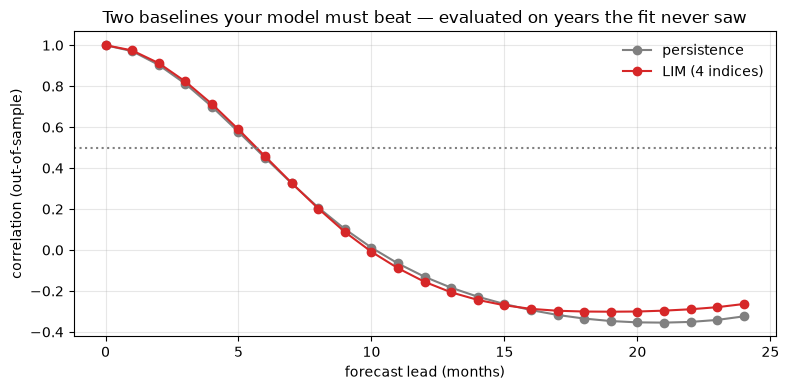

In [17]:
# A simple Linear INverse Model
X = np.stack([indices[name].values for name in NINO])     # shape (4, n_months)
n_train = 1200                                            # 100 years of monthly data
i34 = list(NINO).index("Niño 3.4")

X0, X1 = X[:, :n_train-1], X[:, 1:n_train]
G = (X1 @ X0.T) @ np.linalg.inv(X0 @ X0.T)                # one-month propagator: G = C(1) C(0)^-1
print("propagator spectral radius:", round(max(abs(np.linalg.eigvals(G))), 3), "(<1 = damped, as physics demands)")

lim_skill, pers_skill = [], []
truth_all = X[i34]
for lead in leads:                                        # 'leads' from the persistence cell
    pred = (np.linalg.matrix_power(G, int(lead)) @ X[:, n_train:])[i34]
    truth = truth_all[n_train + lead:]
    lim_skill.append(np.corrcoef(pred[:truth.size], truth)[0, 1])
    pers_skill.append(np.corrcoef(truth_all[n_train:truth.size + n_train], truth)[0, 1])

plt.figure(figsize=(8, 4))
plt.plot(leads, pers_skill, "o-", color="gray", label="persistence")
plt.plot(leads, lim_skill, "o-", color="tab:red", label="LIM (4 indices)")
plt.axhline(0.5, ls=":", color="gray")
plt.xlabel("forecast lead (months)"); plt.ylabel("correlation (out-of-sample)")
plt.title("Two baselines your model must beat — evaluated on years the fit never saw")
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.tight_layout()

_________
# The prediction task.

You will build a machine that forecasts ENSO. Formally: given tropical-Pacific anomaly fields up to some month t, predict the Niño 3.4 index at month t + τ, where τ = [3] months — the lead implied. Start the forecast a few months before today, so we can evaluate at the end on the class.

You will train your model only on CMIP. Evaluate it on held-out simulation years, and use a real-world hindcast file (a model estimating the past by being fit to existing observational data) to issue your forecast. The hindcast files will be shared in Week 5.

Your inputs can be anything you like, e.g. maps, mean values in the boxes... feel free to use persistence and the LIM as baselines to beat.


Deliverables: (1) A 2-page report, (2) Your recording, and (3) your forecast + code.

See syllabus for GenAI policies.




## 8. Our best models (GRU, MLP, and their average) on the U-Net's harness

Our group's best model is a U-Net. For a fair comparison, our earlier best models are trained and scored exactly the way the U-Net was, following the description in our group notes:

| | U-Net harness, used here unchanged |
|---|---|
| Runs | 23 CESM2 runs: historical r1–r11 (1850–2014) and ssp126/245/370/585 of r4, r10, r11 |
| Variables | `tos`, `zos`, `mlotst`, `tauu`, `tauv`, `pr` |
| Grid | 1°, 25°S–25°N × 115°E–65°W (50 × 180 cells) |
| Preprocessing | monthly anomalies vs each member's own 1985–2014 climatology; SST and sea level made *relative* (20°S–20°N mean removed); future runs linearly detrended |
| Split | train: historical 1850–1955 (all 11 members) + future 2020–2100 (12 runs); validation: r4 1961–1980; test: r4 1986–2014 |
| Target | SST anomaly maps 1–12 months ahead; Niño 3.4 computed from the predicted map (main lead: 3 months) |
| Scores | Niño 3.4 correlation and RMSE at each lead; lead-3 map pattern correlation; persistence and a 60-EOF LIM as baselines |

**Data.** `cesm2_unified.nc` (our groupmates' file) holds r4 historical, all 6 variables, on CESM2's 192 × 288 atmosphere grid. It is exactly Section 7's `regridder` applied with `skipna=True`: re-regridding r4 ourselves reproduces its values and land mask. It supplies r4 historical, which contains the validation and test years. The other 22 runs are downloaded and regridded the same way.

**What changes is only the model:** our GRU and MLP from earlier (6-month input window, maps averaged to 2° inside the model, 12 full 1° maps out), 3 seeds each, and their average. Each is trained without and with the two compound variables from our report: the equatorial sea-level gradient (west minus east) and the south-east Pacific wind-stress curl.

**Known gap.** The U-Net's code is not available, and our reconstruction of its truth differs slightly:
- **Jan 1998 relative Niño 3.4:** +3.19 °C here vs their +3.92 °C.
- **Lead-3 persistence error:** 0.84 °C here vs their 1.00 °C.

The likely reason is a NOAA-RONI-style variance rescaling of their index. That multiplies every RMSE by about 1.2 but leaves correlations unchanged. So correlations compare directly; RMSEs compare best as a percentage of persistence.

<sub>Text and code drafted with the help of Claude Opus 5.5 (Anthropic).</sub>

In [18]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.1 The U-Net's data: 23 CESM2 runs x 6 variables on a 1° grid, 25°S–25°N x 115°E–65°W (cached after the first run) ----
VARS6 = ["tos", "zos", "mlotst", "tauu", "tauv", "pr"]
MEMBERS = [f"r{i}i1p1f1" for i in range(1, 12)]                     # 11 historical members
SSP_MEMBERS = ["r4i1p1f1", "r10i1p1f1", "r11i1p1f1"]                 # the 3 members with the 4 future scenarios
RUNS = [(m, "historical") for m in MEMBERS] + [(m, e) for m in SSP_MEMBERS for e in EXPS[1:]]
BOX = xr.Dataset(coords={"lat": np.arange(-24.5, 25), "lon": np.arange(115.5, 295)})   # 50 x 180 cell centres
to_box = xe.Regridder(atmos["historical"], BOX, "bilinear", periodic=True)
CACHE = "unet_harness_cache"
os.makedirs(CACHE, exist_ok=True)

def atmos_grid_field(member, exp, v):
    """One raw monthly field on the 192x288 atmosphere grid, made exactly like the groupmates' cesm2_unified.nc."""
    if (member, exp) == ("r4i1p1f1", "historical"):
        return xr.open_dataset("cesm2_unified.nc")[v]                 # their file (r4 historical)
    row = cat.search(source_id=MODEL, member_id=member, experiment_id=exp, variable_id=v,
                     table_id=["Omon", "Amon"], grid_label="gn").df.iloc[0]
    da = combined_preprocessing(xr.open_zarr(fs.get_mapper(row.zstore), consolidated=True))[v].squeeze(drop=True)
    da = da.sel(time=slice(None, "2100-12"))
    da = da.isel(time=np.unique(da.time.dt.year * 12 + da.time.dt.month, return_index=True)[1])   # drop repeated months
    if row.table_id == "Omon":
        return regridder(da, skipna=True)                             # Section 7's regridder; reproduces their file exactly
    return da.drop_vars(["lat", "lon"]).rename({"y": "lat", "x": "lon"})

for member, exp in RUNS:
    path = f"{CACHE}/{member}_{exp}.npz"
    if os.path.exists(path): continue
    box, trop = [], []
    for v in VARS6:
        da = atmos_grid_field(member, exp, v).load()
        box.append(to_box(da).values)
        if v in ("tos", "zos"):                                       # 20°S–20°N mean, for 'relative' SST and sea level
            band = da.sel(lat=slice(-20, 20))
            trop.append(band.weighted(np.cos(np.deg2rad(band.lat))).mean(("lat", "lon")).values)
    np.savez(path, box=np.stack(box, 1).astype("float32"), trop=np.stack(trop, 1))
    print(f"cached {member} {exp}: {np.stack(box, 1).shape}")
print(f"{len(RUNS)} runs in {CACHE}/")

23 runs in unet_harness_cache/


In [19]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.2 U-Net preprocessing, compound variables, and the train / validation / test split ----
import copy, torch, torch.nn as nn
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
LATB, LONB = BOX.lat.values, BOX.lon.values
NY, NX, WINDOW, LEADS = len(LATB), len(LONB), 6, 12            # 6 input months -> SST maps 1..12 months ahead

def preprocess(member, exp):
    """Anomalies vs this member's 1985–2014 climatology; SST and sea level made relative; future runs detrended."""
    hist, run = np.load(f"{CACHE}/{member}_historical.npz"), np.load(f"{CACHE}/{member}_{exp}.npz")
    box, trop = run["box"], run["trop"]
    mon = np.arange(len(box)) % 12
    a = box - hist["box"][-360:].reshape(30, 12, 6, NY, NX).mean(0)[mon]
    a[:, :2] -= (trop - hist["trop"][-360:].reshape(30, 12, 2).mean(0)[mon])[:, :, None, None]
    if exp != "historical":
        t = (np.arange(len(a)) - (len(a) - 1) / 2)[:, None, None, None]
        a -= np.nanmean(a, 0) + t * np.nansum(t * a, 0) / (t ** 2).sum()
    return a

def compound(a):
    """The report's two compound variables: equatorial sea-level tilt (west minus east) and SE-Pacific wind-stress curl."""
    def box_mean(f, lat, lon):
        return np.nanmean(f[:, (LATB > lat[0]) & (LATB < lat[1])][:, :, (LONB > lon[0]) & (LONB < lon[1])], (1, 2))
    ssh_gradient = box_mean(a[:, 1], (-5, 5), (120, 180)) - box_mean(a[:, 1], (-5, 5), (180, 280))
    m_per_deg = 6.371e6 * np.pi / 180
    curl = (np.gradient(a[:, 4], axis=2) / (m_per_deg * np.cos(np.deg2rad(LATB))[:, None])   # d(tauv)/dx
            - np.gradient(a[:, 3], axis=1) / m_per_deg)                                       # - d(tauu)/dy
    return np.stack([ssh_gradient, box_mean(curl, (-16, -4), (270, 285))], 1)

SPLITS = {"train": [(m, "historical", 1850, 1955) for m in MEMBERS] + [(m, e, 2020, 2100) for m, e in RUNS if e != "historical"],
          "val":   [("r4i1p1f1", "historical", 1961, 1980)],
          "test":  [("r4i1p1f1", "historical", 1986, 2014)]}
first_year = lambda exp: 1850 if exp == "historical" else 2015

a = preprocess("r4i1p1f1", "historical")[:106 * 12]          # r4's training years: normalisation and ocean mask
SCALE, CSCALE, OCEAN = np.nanstd(a, (0, 2, 3)), np.nanstd(compound(a), 0), np.isfinite(a[0, 0])

N = sum(12 * (y1 - y0 + 1) for blocks in SPLITS.values() for *_, y0, y1 in blocks)
DATA = {"maps": torch.zeros((N, 6, NY, NX), dtype=torch.float16, device=DEVICE),   # all blocks back to back, land = 0
        "comp": torch.zeros((N, 2), device=DEVICE)}
IDX, start = {k: [] for k in SPLITS}, 0
for split, blocks in SPLITS.items():
    for member, exp, y0, y1 in blocks:
        a = preprocess(member, exp); i0, n = 12 * (y0 - first_year(exp)), 12 * (y1 - y0 + 1)
        DATA["maps"][start:start + n] = torch.from_numpy(np.nan_to_num(a[i0:i0 + n] / SCALE[:, None, None]).astype("float16"))
        DATA["comp"][start:start + n] = torch.from_numpy(compound(a)[i0:i0 + n] / CSCALE).float()
        last = start + n - (1 if split == "test" else LEADS)  # train/val: all 12 targets inside the block; test: >= 1
        IDX[split] += range(start + WINDOW - 1, last)         # the whole 6-month input window inside the block
        start += n
IDX = {k: torch.tensor(v, device=DEVICE) for k, v in IDX.items()}
TEST_END = start - 1
print({k: len(v) for k, v in IDX.items()}, "forecast start months |", int(OCEAN.sum()), "ocean cells")

{'train': 25265, 'val': 223, 'test': 342} forecast start months | 7962 ocean cells


In [20]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.3 Our two models (as in our earlier work, now predicting all 12 leads) and a plain training loop ----
def inputs(data, t, use_compound):
    """Windows ending at months t -> maps (B, WINDOW, 6, NY, NX), compound scalars (B, WINDOW, 2 or 0), calendar month."""
    w = t[:, None] + torch.arange(1 - WINDOW, 1, device=DEVICE)
    z = data["comp"][w] if use_compound else data["comp"][w][..., :0]
    return data["maps"][w].float(), z, t % 12

targets = lambda t: DATA["maps"][t[:, None] + torch.arange(1, LEADS + 1, device=DEVICE), 0].float()
AREA = torch.tensor(np.cos(np.deg2rad(LATB))[:, None] * OCEAN, dtype=torch.float32, device=DEVICE)
AREA /= AREA.sum()
map_mse = lambda pred, y: (((pred - y) ** 2) * AREA).sum((-2, -1)).mean()   # area-weighted, ocean only, all leads

class MLP(nn.Module):
    """Flatten the 6-month window (maps averaged to 2°, plus any compound scalars) -> one hidden layer -> 12 SST maps."""
    def __init__(s, n_compound, hidden=256, p=0.3):
        super().__init__()
        s.pool, s.month = nn.AvgPool2d(2), nn.Embedding(12, hidden)
        s.inp = nn.Linear(WINDOW * (6 * (NY // 2) * (NX // 2) + n_compound), hidden)
        s.out = nn.Sequential(nn.GELU(), nn.Dropout(p), nn.Linear(hidden, LEADS * NY * NX))
    def forward(s, x, z, m):
        h = torch.cat([s.pool(x.flatten(0, 1)).view(len(x), -1), z.flatten(1)], 1)
        return s.out(s.inp(h) + s.month(m)).view(-1, LEADS, NY, NX)

class GRU(nn.Module):
    """A small CNN embeds each month (maps averaged to 2°); a GRU runs over the 6 months; a linear head emits 12 SST maps."""
    def __init__(s, n_compound, d=256, p=0.3):
        super().__init__()
        s.frame = nn.Sequential(nn.AvgPool2d(2), nn.Conv2d(6, 32, 3, padding=1), nn.GELU(),
                                nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.GELU(),
                                nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.GELU(), nn.Flatten(),
                                nn.Linear(64 * 7 * 23, d))
        s.month, s.drop = nn.Embedding(12, d), nn.Dropout(p)
        s.gru, s.head = nn.GRU(d + n_compound, d, batch_first=True), nn.Linear(d, LEADS * NY * NX)
    def forward(s, x, z, m):
        months = (m[:, None] + torch.arange(1 - WINDOW, 1, device=x.device)) % 12
        h = s.drop(torch.cat([s.frame(x.flatten(0, 1)).view(len(x), WINDOW, -1) + s.month(months), z], 2))
        return s.head(s.drop(s.gru(h)[0][:, -1])).view(-1, LEADS, NY, NX)

@torch.no_grad()
def predict(model, data, t, use_compound):
    """Normalised relative-SST maps (len(t), LEADS, NY, NX) for the windows ending at t."""
    model.eval()
    return torch.cat([model(*inputs(data, b, use_compound)) for b in t.split(128)])

def train(model, use_compound, seed, epochs=15, lr=1e-3, wd=0.05, bs=128):
    """AdamW + one-cycle schedule; keeps the epoch with the lowest validation error (early stopping)."""
    torch.manual_seed(seed); model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd, fused=DEVICE.type != "cpu")
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * -(-len(IDX["train"]) // bs))
    best = (np.inf, None)
    for epoch in range(epochs):
        model.train()
        for t in IDX["train"][torch.randperm(len(IDX["train"]), device=DEVICE)].split(bs):
            loss = map_mse(model(*inputs(DATA, t, use_compound)), targets(t))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        val = float(map_mse(predict(model, DATA, IDX["val"], use_compound), targets(IDX["val"])))
        if val < best[0]: best = (val, copy.deepcopy(model.state_dict()))
    model.load_state_dict(best[1])
    print(f"  {type(model).__name__:<4} compound={use_compound!s:<5} seed {seed}: best validation error {best[0]:.4f}")
    return model

In [21]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.4 Train MLP and GRU, without and with the compound variables, 3 seeds each (like the U-Net's 3 copies) ----
# Training all 12 networks takes ~4 h on an M1 laptop, so the weights are saved and simply reloaded on a re-run.
SEEDS, WEIGHTS = 3, "enso_models_unet_harness.pt"
key = lambda name, c, seed: f"{name}_{'compound' if c else 'six'}_seed{seed}"
saved = torch.load(WEIGHTS, map_location=DEVICE) if os.path.exists(WEIGHTS) else {}
nets = {}
for use_compound in (False, True):
    for Model in (MLP, GRU):
        nets[Model.__name__, use_compound] = []
        for seed in range(SEEDS):
            k = key(Model.__name__, use_compound, seed)
            if k in saved:
                model = Model(2 * use_compound).to(DEVICE); model.load_state_dict(saved[k])
                val = float(map_mse(predict(model, DATA, IDX["val"], use_compound), targets(IDX["val"])))
                print(f"  {Model.__name__:<4} compound={use_compound!s:<5} seed {seed}: loaded, validation error {val:.4f}")
            else:
                model = train(Model(2 * use_compound), use_compound, seed)
                torch.save({**saved, k: model.state_dict()}, WEIGHTS); saved[k] = model.state_dict()
            nets[Model.__name__, use_compound].append(model)

  MLP  compound=False seed 0: loaded, validation error 0.6609


  MLP  compound=False seed 1: loaded, validation error 0.6599


  MLP  compound=False seed 2: loaded, validation error 0.6612


  GRU  compound=False seed 0: loaded, validation error 0.6545


  GRU  compound=False seed 1: loaded, validation error 0.7038


...

  MLP  compound=True  seed 1: loaded, validation error 0.6683


  MLP  compound=True  seed 2: loaded, validation error 0.6630


  GRU  compound=True  seed 0: loaded, validation error 0.6602


  GRU  compound=True  seed 1: loaded, validation error 0.6781


  GRU  compound=True  seed 2: loaded, validation error 0.6576


In [22]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.5 Baselines and scores on the U-Net's test set (r4, 1986–2014), leads 1–12 ----
OCEAN_IDX = torch.tensor(np.flatnonzero(OCEAN), device=DEVICE)
SQRT_W = torch.tensor(np.sqrt(np.cos(np.deg2rad(LATB)))[:, None].repeat(NX, 1).ravel()[np.flatnonzero(OCEAN)],
                      dtype=torch.float32, device=DEVICE)
state = lambda data, t: data["maps"][t, 0].float().flatten(1)[:, OCEAN_IDX] * SQRT_W     # area-weighted SST state

# LIM baseline: 60 EOFs of the relative-SST field and a one-month propagator, fit on the training months
torch.manual_seed(0)                                                       # pca_lowrank is randomised
_, _, EOF = torch.pca_lowrank(state(DATA, IDX["train"]).cpu(), q=60, center=False)
P0, P1 = state(DATA, IDX["train"]).cpu() @ EOF, state(DATA, IDX["train"] + 1).cpu() @ EOF
G1, EOF = torch.linalg.solve(P0.T @ P0, P0.T @ P1).T.to(DEVICE), EOF.to(DEVICE)
def lim_forecast(data, t):
    p, maps = state(data, t) @ EOF, torch.zeros(len(t), LEADS, NY * NX, device=DEVICE)
    for lead in range(LEADS):
        p = p @ G1.T
        maps[:, lead, OCEAN_IDX] = (p @ EOF.T) / SQRT_W
    return maps.view(-1, LEADS, NY, NX)

to_degc = lambda maps: maps.cpu().numpy() * SCALE[0]
B34 = np.cos(np.deg2rad(LATB))[:, None] * ((np.abs(LATB) < 5)[:, None] & ((LONB > 190) & (LONB < 240))[None, :]) * OCEAN
nino34 = lambda f: (f * B34).sum((-2, -1)) / B34.sum()                  # relative Niño 3.4 of (..., NY, NX) maps
corr = lambda a, b: np.corrcoef(a, b)[0, 1]
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
W2 = AREA.cpu().numpy()
pattern = lambda p, y: np.mean((W2 * p * y).sum((-2, -1)) / np.sqrt((W2 * p * p).sum((-2, -1)) * (W2 * y * y).sum((-2, -1))))

CONFIGS = [(n, c) for c in (False, True) for n in ("MLP", "GRU", "GRU+MLP average")]
label = lambda n, c: f"{n}, {'6 variables + compound' if c else '6 variables'}"
def ensemble(name, c, data, t):
    """Normalised mean forecast of all 3 seeds of a model (or of all 6 networks for the GRU+MLP average)."""
    nets_ = nets["MLP", c] + nets["GRU", c] if name == "GRU+MLP average" else nets[name, c]
    return sum(predict(m, data, t, c) for m in nets_) / len(nets_)

t_test = IDX["test"]
FC = {"Persistence": to_degc(DATA["maps"][t_test, 0].float())[:, None].repeat(LEADS, 1),
      "LIM (60 EOFs)": to_degc(lim_forecast(DATA, t_test))}
FC |= {label(n, c): to_degc(ensemble(n, c, DATA, t_test)) for n, c in CONFIGS}

def skill(fc, t=t_test, data=DATA, end=TEST_END):
    """Niño 3.4 correlation and RMSE at every lead, plus the lead-3 map pattern correlation."""
    out = {}
    for lead in range(1, LEADS + 1):
        ok = (t + lead <= end).cpu().numpy()
        y = to_degc(data["maps"][t[ok] + lead, 0].float())
        out[lead] = (corr(nino34(fc[ok, lead - 1]), nino34(y)), rmse(nino34(fc[ok, lead - 1]), nino34(y)))
        if lead == 3: out["pattern"] = pattern(fc[ok, 2], y)
    return out

SKILL = {k: skill(v) for k, v in FC.items()}
UNET = {"U-Net, all 6 variables (reported)": {3: (0.97, 0.40), 6: (0.92, 0.63), 12: (0.80, 1.00), "pattern": 0.81},
        "U-Net, SST + sea level (reported)": {3: (0.96, 0.42), 6: (0.92, 0.64), 12: (0.83, 0.99)},
        "LIM, 60 EOFs (reported)": {3: (0.94, 0.51), 6: (0.84, 0.85), 12: (0.66, 1.21), "pattern": 0.78},
        "Persistence (reported)": {3: (0.79, 1.00), 6: (0.40, 1.71), 12: (-0.21, 2.44)}}
def row(s, persistence):
    return {**{f"lead {l}: corr / RMSE": "%.2f / %.2f" % s[l] for l in (3, 6, 12)},
            "lead 3 RMSE vs persistence": f"{100 * (s[3][1] / persistence[3][1] - 1):+.0f}%",
            "lead 3 pattern corr": "%.2f" % s["pattern"] if "pattern" in s else "–"}
table = pd.DataFrame({k: row(s, SKILL["Persistence"]) for k, s in SKILL.items()} |
                     {k: row(s, UNET["Persistence (reported)"]) for k, s in UNET.items()}).T
display(table)

# The final model is chosen on validation (r4 1961–1980) only, among the 6 configurations
val_err = {(n, c): float(map_mse(ensemble(n, c, DATA, IDX["val"]), targets(IDX["val"]))) for n, c in CONFIGS}
FINAL_CFG = min(val_err, key=val_err.get)
FINAL = label(*FINAL_CFG)
print("validation error:", {label(*k): round(v, 4) for k, v in val_err.items()}, "\n-> final model:", FINAL)

,lead 3: corr / RMSE,lead 6: corr / RMSE,lead 12: corr / RMSE,lead 3 RMSE vs persistence,lead 3 pattern corr
Persistence,0.80 / 0.84,0.40 / 1.45,-0.20 / 2.08,+0%,0.64
LIM (60 EOFs),0.95 / 0.43,0.86 / 0.69,0.62 / 1.06,-49%,0.79
"MLP, 6 variables",0.96 / 0.36,0.91 / 0.56,0.78 / 0.83,-57%,0.82
"GRU, 6 variables",0.96 / 0.37,0.92 / 0.55,0.85 / 0.81,-56%,0.80
"GRU+MLP average, 6 variables",0.97 / 0.35,0.92 / 0.53,0.83 / 0.78,-59%,0.82
"MLP, 6 variables + compound",0.96 / 0.37,0.91 / 0.56,0.79 / 0.81,-57%,0.82
"GRU, 6 variables + compound",0.97 / 0.35,0.92 / 0.54,0.81 / 0.84,-59%,0.81
"GRU+MLP average, 6 variables + compound",0.97 / 0.34,0.92 / 0.52,0.82 / 0.79,-60%,0.82
"U-Net, all 6 variables (reported)",0.97 / 0.40,0.92 / 0.63,0.80 / 1.00,-60%,0.81
"U-Net, SST + sea level (reported)",0.96 / 0.42,0.92 / 0.64,0.83 / 0.99,-58%,–


validation error: {'MLP, 6 variables': 0.6488, 'GRU, 6 variables': 0.6349, 'GRU+MLP average, 6 variables': 0.62, 'MLP, 6 variables + compound': 0.6505, 'GRU, 6 variables + compound': 0.63, 'GRU+MLP average, 6 variables + compound': 0.6235} 
-> final model: GRU+MLP average, 6 variables


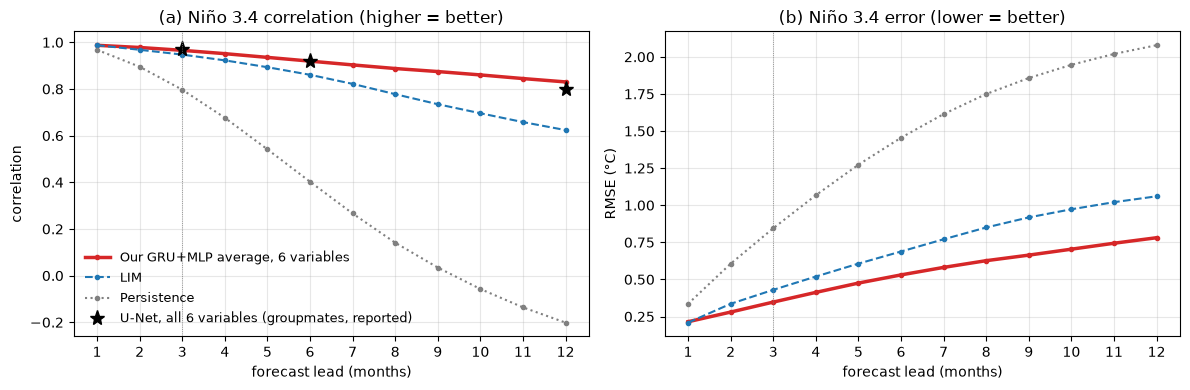

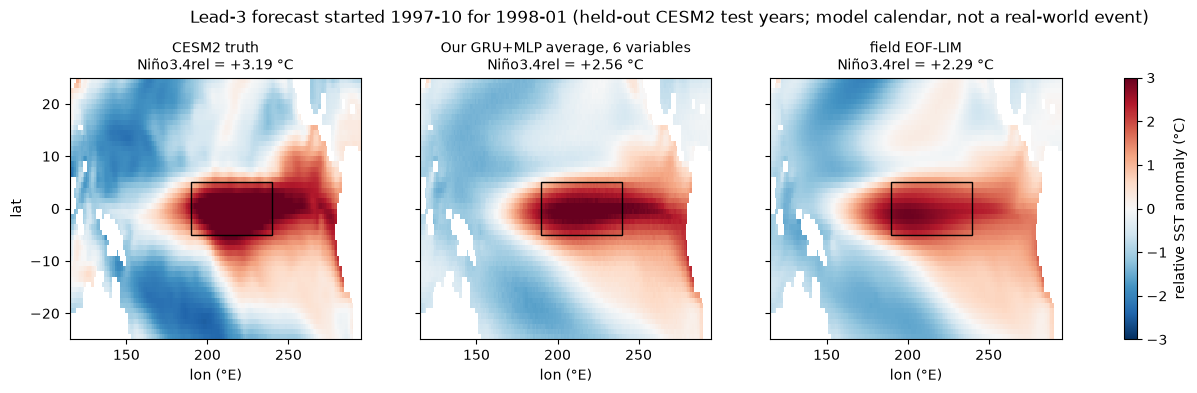

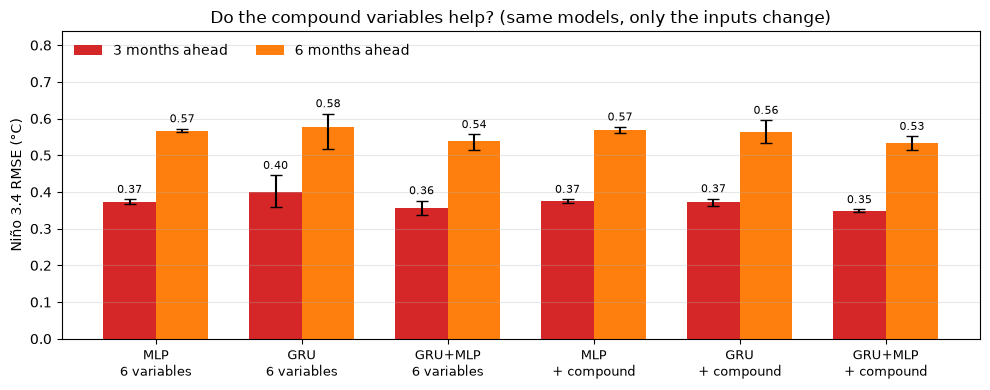

In [23]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 8.6 The U-Net's three figures, redone for our model ----
leads = np.arange(1, LEADS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, legend, style in [(FINAL, f"Our {FINAL}", dict(color="tab:red", lw=2.5)),
                            ("LIM (60 EOFs)", "LIM", dict(color="tab:blue", ls="--")),
                            ("Persistence", "Persistence", dict(color="gray", ls=":"))]:
    for j, ax in enumerate(axes):
        ax.plot(leads, [SKILL[name][l][j] for l in leads], marker=".", label=legend, **style)
axes[0].plot([3, 6, 12], [UNET["U-Net, all 6 variables (reported)"][l][0] for l in (3, 6, 12)], "k*", ms=11,
             label="U-Net, all 6 variables (groupmates, reported)")
for ax, title, ylabel in zip(axes, ["(a) Niño 3.4 correlation (higher = better)", "(b) Niño 3.4 error (lower = better)"],
                             ["correlation", "RMSE (°C)"]):
    ax.axvline(3, color="gray", lw=0.6, ls=":"); ax.set_xticks(leads); ax.grid(alpha=0.3)
    ax.set_xlabel("forecast lead (months)"); ax.set_ylabel(ylabel); ax.set_title(title)
axes[0].legend(frameon=False, loc="lower left", fontsize=9); plt.tight_layout()

# Figure 2: the whole map, strongest test-year El Niño, 3 months ahead
start = TEST_END + 1 - 12 * (2014 - 1986 + 1) + 12 * (1997 - 1986) + 9     # forecast started 1997-10
k = int((t_test == start).nonzero())
panels = {"CESM2 truth": to_degc(DATA["maps"][start + 3, 0].float()), f"Our {FINAL}": FC[FINAL][k, 2], "field EOF-LIM": FC["LIM (60 EOFs)"][k, 2]}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
for ax, (name, f) in zip(axes, panels.items()):
    m = ax.pcolormesh(LONB, LATB, np.where(OCEAN, f, np.nan), cmap="RdBu_r", vmin=-3, vmax=3)
    ax.add_patch(mpatches.Rectangle((190, -5), 50, 10, fill=False, color="k"))
    ax.set_title(f"{name}\nNiño3.4rel = {nino34(f):+.2f} °C", fontsize=10); ax.set_xlabel("lon (°E)")
axes[0].set_ylabel("lat"); fig.colorbar(m, ax=axes, label="relative SST anomaly (°C)")
fig.suptitle("Lead-3 forecast started 1997-10 for 1998-01 (held-out CESM2 test years; model calendar, not a real-world event)", y=1.08)

# Figure 3: do the compound variables help? Bars = mean over the 3 network copies, whiskers = min..max over copies
def copies(name, c):
    p = lambda n: [to_degc(predict(m, DATA, t_test, c)) for m in nets[n, c]]
    return [(a + b) / 2 for a, b in zip(p("MLP"), p("GRU"))] if name == "GRU+MLP" else p(name)
configs = [(n, c) for c in (False, True) for n in ("MLP", "GRU", "GRU+MLP")]
per_copy = {cfg: [skill(f) for f in copies(*cfg)] for cfg in configs}
fig, ax = plt.subplots(figsize=(10, 4))
for j, (lead, color) in enumerate([(3, "tab:red"), (6, "tab:orange")]):
    for i, cfg in enumerate(configs):
        r = np.array([s[lead][1] for s in per_copy[cfg]])
        ax.bar(i + (j - 0.5) * 0.36, r.mean(), 0.36, color=color, label=f"{lead} months ahead" if i == 0 else None,
               yerr=[[r.mean() - r.min()], [r.max() - r.mean()]], capsize=4)
        ax.text(i + (j - 0.5) * 0.36, r.max() + 0.01, f"{r.mean():.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(configs)), [f"{n}\n{'+ compound' if c else '6 variables'}" for n, c in configs], fontsize=9)
ax.set_ylim(0, 1.3 * ax.get_ylim()[1]); ax.grid(axis="y", alpha=0.3)
ax.set_ylabel("Niño 3.4 RMSE (°C)"); ax.legend(frameon=False, loc="upper left", ncol=2)
ax.set_title("Do the compound variables help? (same models, only the inputs change)"); plt.tight_layout()

**Results on the U-Net's test set (r4, 1986–2014).**

- **The harness matches the U-Net's.** Our persistence and 60-EOF LIM have the same correlations the U-Net report gives (persistence 0.80 / 0.40 / −0.20 at leads 3 / 6 / 12, reported 0.79 / 0.40 / −0.21; LIM 0.95 vs 0.94 at lead 3). The LIM is also 49% better than persistence in both. Only the RMSE scale differs: theirs is about 1.18× ours for every baseline.
- **Our final model ties the U-Net.** The validation years picked the GRU+MLP average with the 6 variables, without the compound variables.

| | lead 3: corr / RMSE vs persistence | lead 6: corr / RMSE vs persistence | lead 12: corr / RMSE vs persistence | lead-3 pattern corr |
|---|---|---|---|---|
| Our GRU+MLP average | 0.97 / −59% | 0.92 / −64% | 0.83 / −62% | 0.82 |
| U-Net, all 6 variables (reported) | 0.97 / −60% | 0.92 / −63% | 0.80 / −59% | 0.81 |

  Its raw RMSEs are lower (0.35 vs 0.40 °C at lead 3), but that is the index-scale difference above, not skill.
- **The compound variables don't help.** Validation error is 0.620 without them and 0.624 with. On the test set the difference is smaller than the spread between network copies (Figure 3). Sea-level tilt and wind-stress curl are already in the `zos`, `tauu` and `tauv` maps the models see.
- **GRU vs MLP: about the same at short leads.** Averaging them is slightly better than either alone. The GRU holds up better at long leads (lead-12 correlation 0.85 vs 0.78). One GRU copy (seed 1) trained worse, which explains its long whisker.
- **Bottom line:** with identical data, a simple GRU/MLP average does as well as the U-Net. The 23 runs of training data matter more than the architecture.

<sub>Text and code drafted with the help of Claude Opus 5.5 (Anthropic).</sub>

## 9. The real world: the same pipeline on the professor's GODAS/ERA5 file

The file `ecs289g_realworld_inputs_CESM2.nc` (Oct 2016 – Sep 2026) is already on the same 192 × 288 grid, so it goes through the identical steps: the 1° box, relative SST and sea level, the compound variables, and the same normalisation. Two choices differ from the CESM2 harness:
- **Anomaly base:** the file has no 1985–2014 data, so anomalies are taken against its own 10 complete years.
- **No refitting:** nothing is fit or tuned on this file. The final model from Section 8 is used as is.

The hindcasts start every month whose 6-month window is available (Mar 2017 onward) and are verified up to Sep 2026. The real forecast starts from the window ending Sep 2026 and runs 12 months ahead.

<sub>Text and code drafted with the help of Claude Opus 5.5 (Anthropic).</sub>

,lead 3: corr / RMSE,lead 6: corr / RMSE,lead 12: corr / RMSE,lead 3 RMSE vs persistence,lead 3 pattern corr
Persistence,0.71 / 0.50,0.27 / 0.79,-0.16 / 1.01,+0%,0.47
LIM (60 EOFs),0.87 / 0.38,0.76 / 0.52,0.43 / 0.68,-23%,0.55
"MLP, 6 variables",0.87 / 0.53,0.70 / 0.72,0.14 / 1.10,+7%,0.49
"GRU, 6 variables",0.86 / 0.48,0.73 / 0.60,0.52 / 0.64,-4%,0.51
"GRU+MLP average, 6 variables",0.88 / 0.47,0.75 / 0.59,0.33 / 0.79,-5%,0.53
"MLP, 6 variables + compound",0.88 / 0.53,0.68 / 0.74,0.12 / 1.09,+7%,0.49
"GRU, 6 variables + compound",0.86 / 0.50,0.67 / 0.66,0.47 / 0.70,-0%,0.47
"GRU+MLP average, 6 variables + compound",0.88 / 0.48,0.72 / 0.62,0.31 / 0.80,-3%,0.51


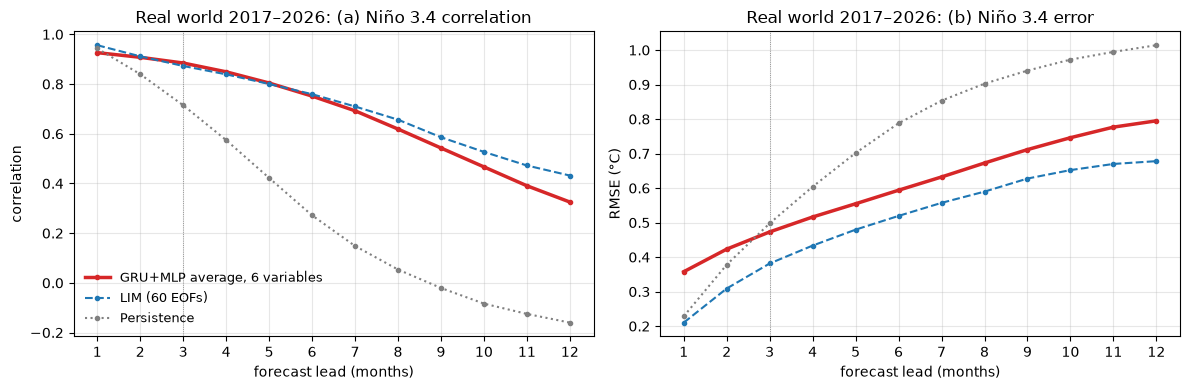

In [24]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 9.1 The real-world file through the same pipeline, and hindcast skill at leads 1–12 ----
REAL = xr.open_dataset("ecs289g_realworld_inputs_CESM2.nc")       # GODAS/ERA5, Oct 2016 – Sep 2026, same 192x288 grid
box = np.stack([to_box(REAL[v]).values for v in VARS6], 1)
band = REAL[["tos", "zos"]].sel(lat=slice(-20, 20))
trop = band.weighted(np.cos(np.deg2rad(band.lat))).mean(("lat", "lon")).to_array().values.T
mon = REAL.time.dt.month.values - 1
anom = lambda x: x - np.stack([x[mon == k].mean(0) for k in range(12)])[mon]   # vs the file's own 10-year climatology
real_anom, trop_anom = anom(box), anom(trop)
real_anom[:, :2] -= trop_anom[:, :, None, None]                                 # relative SST and sea level
REAL_DATA = {"maps": torch.tensor(np.nan_to_num(real_anom / SCALE[:, None, None]), dtype=torch.float16, device=DEVICE),
             "comp": torch.tensor(compound(real_anom) / CSCALE, dtype=torch.float32, device=DEVICE)}

t_real = torch.arange(WINDOW - 1, len(mon) - 1, device=DEVICE)          # every window with at least one verifiable lead
REAL_FC = {"Persistence": to_degc(REAL_DATA["maps"][t_real, 0].float())[:, None].repeat(LEADS, 1),
           "LIM (60 EOFs)": to_degc(lim_forecast(REAL_DATA, t_real))}
REAL_FC |= {label(n, c): to_degc(ensemble(n, c, REAL_DATA, t_real)) for n, c in CONFIGS}
REAL_SKILL = {k: skill(v, t_real, REAL_DATA, len(mon) - 1) for k, v in REAL_FC.items()}
display(pd.DataFrame({k: row(s, REAL_SKILL["Persistence"]) for k, s in REAL_SKILL.items()}).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, style in [(FINAL, dict(color="tab:red", lw=2.5)), ("LIM (60 EOFs)", dict(color="tab:blue", ls="--")),
                    ("Persistence", dict(color="gray", ls=":"))]:
    for j, ax in enumerate(axes):
        ax.plot(leads, [REAL_SKILL[name][l][j] for l in leads], marker=".", label=name, **style)
for ax, title, ylabel in zip(axes, ["(a) Niño 3.4 correlation", "(b) Niño 3.4 error"], ["correlation", "RMSE (°C)"]):
    ax.axvline(3, color="gray", lw=0.6, ls=":"); ax.set_xticks(leads); ax.grid(alpha=0.3)
    ax.set_xlabel("forecast lead (months)"); ax.set_ylabel(ylabel); ax.set_title(f"Real world 2017–2026: {title}")
axes[0].legend(frameon=False, loc="lower left", fontsize=9); plt.tight_layout()

,Oct 2026,Nov 2026,Dec 2026,Jan 2027,Feb 2027,Mar 2027,Apr 2027,May 2027,Jun 2027,Jul 2027,Aug 2027,Sep 2027
relative Niño 3.4 (°C),2.96,3.22,3.30,3.19,2.92,2.49,1.91,1.25,0.54,-0.13,-0.72,-1.22
"conventional Niño 3.4 (°C), latest tropical-mean anomaly added",3.50,3.76,3.84,3.73,3.46,3.03,2.45,1.79,1.08,0.41,-0.18,-0.68


saved enso_forecast_CESM2_group5_unet_harness.nc


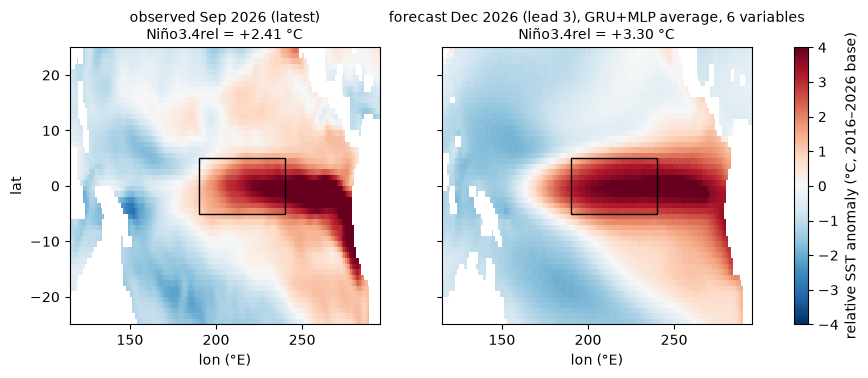

In [25]:
# Code written with the help of Claude Opus 5.5 (Anthropic).
# ---- 9.2 The forecast: relative SST anomaly maps for Oct 2026 – Sep 2027 from the 6 months ending Sep 2026 ----
forecast = to_degc(ensemble(*FINAL_CFG, REAL_DATA, torch.tensor([len(mon) - 1], device=DEVICE)))[0]
months = pd.date_range("2026-10", periods=LEADS, freq="MS")
display(pd.DataFrame({"relative Niño 3.4 (°C)": nino34(forecast),
                      "conventional Niño 3.4 (°C), latest tropical-mean anomaly added": nino34(forecast) + trop_anom[-1, 0]},
                     index=months.strftime("%b %Y")).T.round(2))

latest = np.where(OCEAN, real_anom[-1, 0], np.nan)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, f) in zip(axes, {"observed Sep 2026 (latest)": latest, f"forecast Dec 2026 (lead 3), {FINAL}": forecast[2]}.items()):
    m = ax.pcolormesh(LONB, LATB, np.where(OCEAN, f, np.nan), cmap="RdBu_r", vmin=-4, vmax=4)
    ax.add_patch(mpatches.Rectangle((190, -5), 50, 10, fill=False, color="k"))
    ax.set_title(f"{name}\nNiño3.4rel = {nino34(np.nan_to_num(f)):+.2f} °C", fontsize=10); ax.set_xlabel("lon (°E)")
axes[0].set_ylabel("lat"); fig.colorbar(m, ax=axes, label="relative SST anomaly (°C, 2016–2026 base)")

xr.Dataset({"relative_sst_anomaly": (("time", "lat", "lon"), np.where(OCEAN, forecast, np.nan), {"units": "degC"}),
            "relative_nino34": ("time", nino34(forecast), {"units": "degC"})},
           coords={"time": months, "lat": LATB, "lon": LONB},
           attrs={"model": FINAL, "initial_month": "2026-09", "anomaly_base": "2016-10 to 2026-09 monthly climatology",
                  "relative": "tropical-mean (20S-20N) SST anomaly removed"}).to_netcdf("enso_forecast_CESM2_group5_unet_harness.nc")
print("saved enso_forecast_CESM2_group5_unet_harness.nc")

**Real-world results (2017–2026 hindcasts, relative Niño 3.4).**

| | lead 3: corr / RMSE | lead 6: corr / RMSE | lead 12: corr / RMSE |
|---|---|---|---|
| Our GRU+MLP average | 0.88 / 0.47 °C | 0.75 / 0.59 °C | 0.33 / 0.79 °C |
| LIM (60 EOFs) | 0.87 / 0.38 °C | 0.76 / 0.52 °C | 0.43 / 0.68 °C |
| Persistence | 0.71 / 0.50 °C | 0.27 / 0.79 °C | −0.16 / 1.01 °C |

- **Correlation:** our model matches the field LIM up to about 6 months ahead, and both clearly beat persistence.
- **Error:** the LIM is lower at every lead. The CESM2-trained networks predict events that are too strong, because CESM2's ENSO is too strong. Correcting this would mean tuning on this file, which we don't do.
- **Long leads:** the GRU alone is the best model at lead 12 (0.52 / 0.64 °C).
- **Small sample:** ten years hold only a few ENSO events, so these real-world rankings are uncertain.

**Forecast from the window ending Sep 2026.** Relative Niño 3.4 (2016–2026 base) is predicted to peak at **+3.30 °C in Dec 2026**, after +2.96 in Oct and +3.22 in Nov. It then decays through spring 2027 and turns La Niña-like by Sep 2027 (−1.22 °C).

Adding back the latest observed tropical-mean SST anomaly (+0.54 °C) gives a conventional Niño 3.4 of about +3.8 °C for Dec 2026. The maps and index are saved in `enso_forecast_CESM2_group5_unet_harness.nc`.

<sub>Text and code drafted with the help of Claude Opus 5.5 (Anthropic).</sub>